# MLP + entity embeddings

## 1. Objective

Train a neural network on the structured attributes only, learning dense embeddings for high-cardinality location columns, and compare it with the classical models under the shared temporal protocol. It is also the tabular branch reused by the fusion model.

## 2. Experimental Setup

Run `python -m experiments.prepare` once from the repository root. The notebook then executes from the repository root, `models/`, or Google Colab (the first cell mounts Drive and moves into the unzipped bundle; see `EXPERIMENTS.md`). It never downloads data implicitly.

Reproducibility: Python, NumPy and PyTorch are seeded with the shared seed, the training `DataLoader` shuffles with its own seeded generator, and cuDNN runs in deterministic mode. Outside Colab the model runs on CPU. Apple's MPS backend is skipped on purpose, because for a
network of this size it is not faster and its kernels are not deterministic. Re-running the notebook on the same machine reproduces every number exactly; a GPU may differ in the last digits because floating-point additions are ordered differently.


In [ ]:
from pathlib import Path
import os
import sys

try:  
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir("/content/drive/MyDrive/261-dl/models")
except ImportError:
    pass

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "experiments").is_dir() and (path / "requirements.txt").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ["OMP_NUM_THREADS"] = "2"
os.environ["OPENBLAS_NUM_THREADS"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown
from experiments.data import load_data, SEED, NUMERIC, CATEGORICAL
from experiments.evaluation import (
    select_candidate, inverse_log, record_result, diagnostics, comparison_table, environment,
)
from experiments.deep import (
    TabularEncoder, TabularDataset, EmbeddingMLP, embedding_dim, make_loader,
    predict_log, fit, set_seed, get_device,
)

set_seed(SEED)
torch.set_num_threads(2)
DEVICE = get_device()
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "savefig.dpi": 300})
parts, manifest = load_data()
train, validation, test = (parts[name] for name in ["train", "validation", "test"])
y_train = train.price.to_numpy()
y_validation = validation.price.to_numpy()
log_y_train = np.log1p(y_train)
log_y_validation = np.log1p(y_validation)
display(pd.Series({"Seed": SEED, "Device": str(DEVICE), "Dataset": manifest["source"]["dataset"],
                   "Revision": manifest["source"]["revision"],
                   "Split SHA-256": manifest["split_sha256"]}, name="Setting").to_frame())
display(pd.Series(environment()["packages"], name="Installed version").to_frame())


,Setting
Seed,42
Device,cpu
Dataset,vduydong/vietnam-real-estates
Revision,a9a66ffa985edcf76b4be59ae2c6f5b1db889c38
Split SHA-256,15340296092993fac87fe7f2cd02c9635da706a0510a79...


,Installed version
numpy,1.26.4
pandas,2.2.3
pyarrow,18.1.0
scikit-learn,1.5.2
lightgbm,4.5.0
catboost,1.2.7
matplotlib,3.9.2
torch,2.15.0
transformers,None


## 3. Dataset Overview

The verified cohort is split chronologically into 70% training, 15% validation and 15% test
listings. The asking-price distribution is extremely right-skewed: the training median is
7.4 billion VND, while the maximum is about 1,500 times larger. This motivates modelling the
logarithm of price (Section 4).

In [2]:
display(pd.DataFrame([
    {"Split": name, "Listings": len(frame),
     "First publication (UTC)": frame.published_at.min(),
     "Last publication (UTC)": frame.published_at.max()}
    for name, frame in parts.items()
]).set_index("Split"))
display(train.price.describe(percentiles=[.01, .5, .99]).rename("Training asking price (VND)").to_frame())


,Listings,First publication (UTC),Last publication (UTC)
Split,,,
train,41663,2025-06-01 01:25:24.427000+00:00,2025-11-04 13:39:57.561000+00:00
validation,8928,2025-11-04 13:44:57.945000+00:00,2025-12-02 22:12:39.046000+00:00
test,8928,2025-12-02 22:13:20.406000+00:00,2025-12-30 23:48:26.266000+00:00


,Training asking price (VND)
count,4.166300e+04
mean,1.622745e+10
std,9.883617e+10
min,3.200000e+06
1%,5.500000e+08
50%,7.400000e+09
99%,1.300000e+11
max,1.120000e+13


## 4. Data Preprocessing

The assertions below repeat the leakage checks of the shared protocol: no target-derived input, strictly increasing publication time across partitions, and no identity-proxy group shared
between partitions.

Every statistic in this section is estimated on the **training partition only** and then
applied unchanged to validation and test.

**Numeric attributes** (`area`, floor/room counts, frontage, depth, road width):

1. **`log1p` transform.** Physical sizes are heavy-tailed (one recorded frontage is 2,000,000 m).
   The logarithm compresses the tail so that a single value cannot dominate a feature's scale.
2. **Winsorization** at the training 0.5% and 99.5% quantiles (on the log scale), which bounds
   implausible entries without deleting rows.
3. **Median imputation plus a missingness indicator.** Values are not missing at random:
   apartments rarely report frontage, land plots rarely report bedrooms. Imputation alone would
   erase this signal; the 0/1 indicator column gives it back to the network.
4. **Standardization** to zero mean and unit variance. Gradient descent uses one learning rate
   for all weights; inputs on very different scales produce an ill-conditioned loss surface,
   on which gradients zig-zag and convergence is slow.

This yields 14 dense inputs: 7 scaled values and 7 missingness flags.

**Categorical attributes** are mapped to integer indices for the embedding layers (Section 5).


In [3]:
assert set(NUMERIC + CATEGORICAL).isdisjoint({"price", "price_per_m2", "group_id", "row_id", "split"})
assert train.published_at.max() < validation.published_at.min()
assert validation.published_at.max() < test.published_at.min()
assert set(train.group_id).isdisjoint(validation.group_id)
assert set(train.group_id).isdisjoint(test.group_id)
assert set(validation.group_id).isdisjoint(test.group_id)


In [4]:
encoder = TabularEncoder(min_frequency=5).fit(train)          # training rows only
train_dense, train_codes = encoder.transform(train)
validation_dense, validation_codes = encoder.transform(validation)
test_dense, test_codes = encoder.transform(test)

display(pd.DataFrame({
    "Index size (kept levels + rare/unseen)": encoder.cardinalities,
    "Embedding dimension": [embedding_dim(n) for n in encoder.cardinalities],
    "Validation rare/unseen share": (validation_codes == 0).mean(axis=0),
    "Test rare/unseen share": (test_codes == 0).mean(axis=0),
}, index=CATEGORICAL).style.format({"Validation rare/unseen share": "{:.3f}",
                                    "Test rare/unseen share": "{:.3f}"}))
display(pd.DataFrame({
    "Training missing fraction": train[NUMERIC].isna().mean(),
    "Lower clip (raw units)": np.expm1(encoder.lower_),
    "Upper clip (raw units)": np.expm1(encoder.upper_),
    "Median fill (raw units)": np.expm1(encoder.median_),
}).style.format("{:,.3f}"))
print("Dense input:", train_dense.shape, "| categorical codes:", train_codes.shape)


,Index size (kept levels + rare/unseen),Embedding dimension,Validation rare/unseen share,Test rare/unseen share
property_type_name,6,4,0.000,0.000
province_name,57,15,0.001,0.000
district_name,254,32,0.015,0.008
ward_name,1033,32,0.082,0.063
street_name,1338,32,0.193,0.184
project_name,735,32,0.094,0.101
house_direction,14,7,0.000,0.000
balcony_direction,14,7,0.000,0.000


,Training missing fraction,Lower clip (raw units),Upper clip (raw units),Median fill (raw units)
area,0.000,21.000,"5,083.823",80.000
floor_count,0.766,1.000,9.000,4.000
frontage_width,0.464,3.000,68.000,5.000
house_depth,0.975,4.411,118.704,19.790
road_width,0.819,2.000,60.000,6.000
bedroom_count,0.468,1.000,20.000,3.000
bathroom_count,0.502,1.000,19.176,3.000


Dense input: (41663, 14) | categorical codes: (41663, 8)


## 5. Feature Engineering

**Entity embeddings instead of one-hot encoding.** One-hot encoding `street_name` would create
thousands of sparse columns, and each street would be learned independently. An embedding layer
stores a trainable matrix $E \in \mathbb{R}^{n \times d}$ and maps level $i$ to row $E_i$.

**Rare and unseen levels share index 0.** A level seen fewer than 5 times in training would
receive an almost untrained, noisy vector. All such levels are pooled into index 0, which is
trained on every rare listing and therefore learns a meaningful "uncommon location" vector.
Levels first seen in validation or test map to the same index. The vocabulary is built from
training data only; the table above reports how often validation and test fall back to it
(e.g. street names about 19%).

**Hierarchical keys.** Administrative names repeat across the country (many provinces have a
"Phường 1"). District, ward, street and project names are therefore qualified by their parent
levels (`province|district|ward`) before the vocabulary is built, so identically named places
in different provinces receive different embeddings.


## 6. Model Implementation

    [7 scaled numerics + 7 missing flags] ─┐
    [8 embeddings → dropout] ──────────────┴─ concat → Linear → SiLU
        → ResidualBlock × k → BatchNorm → SiLU → Linear → log1p(price)

- **Residual blocks** compute $h + F(h)$, with
  $F$ = BatchNorm → SiLU → Linear → BatchNorm → SiLU → Dropout → Linear.
  The identity path lets gradients bypass $F$, avoiding the degradation of deep plain networks
  (He et al., 2016). The last layer of each $F$ is initialized to zero, so every block starts as
  the identity map: the network begins shallow and uses its depth only as training requires.
- **Pre-activation BatchNorm** keeps each layer's input distribution stable and tolerates
  larger learning rates.
- **SiLU** ($x\,\sigma(x)$) is smooth and, unlike ReLU, has no region of permanently zero
  gradient.
- **Dropout** inside each block and on the concatenated embeddings regularizes the network and
  discourages reliance on a single high-cardinality column.
- **Output bias initialized to the mean training log price.** The first epochs are not spent
  learning a constant offset of about 22.8; the check below confirms that the untrained network
  already predicts 22.73 against a target mean of 22.76.


In [5]:
def build_model(parameters):
    return EmbeddingMLP(
        n_dense=train_dense.shape[1], cardinalities=encoder.cardinalities,
        hidden=parameters["hidden"], blocks=parameters["blocks"],
        dropout=parameters["dropout"], embedding_dropout=parameters["embedding_dropout"],
        target_mean=float(log_y_train.mean()),
    ).to(DEVICE)


## 7. Hyperparameter Configuration

The four candidates are prespecified. Each one changes a single aspect of `BASE`, so that any
difference can be attributed to it:

| Candidate | Change from `BASE` | Question |
|---|---|---|
| 0 | none (Huber loss, 256 units, 2 blocks) | reference |
| 1 | MSE loss | does a robust loss matter? |
| 2 | 512 units, 3 blocks, dropout 0.3 | does capacity help? |
| 3 | no embedding dropout, weaker weight decay | is the regularization necessary? |

**Target and loss.** All candidates fit $\log(1+\text{price})$, whose training range of 15–30
corresponds to prices differing by a factor of about $e^{15}$. Model selection uses MAE in VND.
The minimizer of $\mathbb{E}|y-c|$ is the conditional **median**, and the median commutes with
any increasing transformation: $\operatorname{median}(\log y) = \log \operatorname{median}(y)$.
An absolute-type loss on log prices therefore targets the same quantity that VND MAE rewards.
MSE on log prices targets $\mathbb{E}[\log y]$ (the geometric mean), which coincides with the
median only when the conditional log-price distribution is symmetric. The **Huber** loss is
quadratic for errors below $\delta = 1$ (smooth optimization) and linear above it (robust to
mislabeled prices, e.g. a unit entered as billions instead of millions); $\delta = 1$ on the
log scale corresponds to a factor of about 2.7.


In [6]:
BASE = {"hidden": 256, "blocks": 2, "dropout": 0.2, "embedding_dropout": 0.1,
        "loss": "huber", "huber_delta": 1.0, "lr": 2e-3, "weight_decay": 1e-4,
        "batch_size": 512}
candidates = [
    BASE,
    {**BASE, "loss": "mse"},
    {**BASE, "hidden": 512, "blocks": 3, "dropout": 0.3},
    {**BASE, "embedding_dropout": 0.0, "weight_decay": 1e-5},
]
display(pd.DataFrame(candidates))

set_seed(SEED)
probe = build_model(BASE)
print(probe)
print(f"Trainable parameters: {sum(p.numel() for p in probe.parameters()):,}")
with torch.no_grad():
    probe.eval()
    first = probe(torch.as_tensor(train_dense[:8]).to(DEVICE), torch.as_tensor(train_codes[:8]).to(DEVICE))
print(f"Initial prediction mean {first.mean().item():.3f} vs training log-price mean {log_y_train.mean():.3f}")


,hidden,blocks,dropout,embedding_dropout,loss,huber_delta,lr,weight_decay,batch_size
0,256,2,0.2,0.1,huber,1.0,0.002,0.00010,512
1,256,2,0.2,0.1,mse,1.0,0.002,0.00010,512
2,512,3,0.3,0.1,huber,1.0,0.002,0.00010,512
3,256,2,0.2,0.0,huber,1.0,0.002,0.00001,512


EmbeddingMLP(
  (embeddings): ModuleList(
    (0): Embedding(6, 4)
    (1): Embedding(57, 15)
    (2): Embedding(254, 32)
    (3): Embedding(1033, 32)
    (4): Embedding(1338, 32)
    (5): Embedding(735, 32)
    (6-7): 2 x Embedding(14, 7)
  )
  (embedding_dropout): Dropout(p=0.1, inplace=False)
  (input): Sequential(
    (0): Linear(in_features=175, out_features=256, bias=True)
    (1): SiLU()
  )
  (blocks): Sequential(
    (0): ResidualBlock(
      (branch): Sequential(
        (0): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (1): SiLU()
        (2): Linear(in_features=256, out_features=256, bias=True)
        (3): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (4): SiLU()
        (5): Dropout(p=0.2, inplace=False)
        (6): Linear(in_features=256, out_features=256, bias=True)
      )
    )
    (1): ResidualBlock(
      (branch): Sequential(
        (0): BatchNorm1d(256, e

## 8. Model Training

- **Mini-batch training** with batch size 512, shuffled each epoch by a seeded generator.
- **AdamW** divides each gradient by a running estimate of its
  magnitude; an L2 penalty added to the loss is divided the same way, so weights with large
  gradients are barely regularized. AdamW decouples weight decay and applies
  $w \leftarrow w - \eta \lambda w$ directly, shrinking all weights uniformly.
- **Gradient clipping** at global L2 norm 1 bounds the update size when a batch contains
  extreme or mislabeled prices.
- **ReduceLROnPlateau** halves the learning rate after 4 epochs without validation improvement,
  so the optimizer takes finer steps once it reaches a basin.
- **Early stopping** (patience 12) monitors validation MAE of log price, the log-scale
  counterpart of the selection metric, and restores the best weights. Stopping early acts as a
  regularizer: for linear models it approximately constrains the weight norm like L2.

Validation data drive early stopping, the learning-rate schedule and candidate selection, so the
selected validation score is optimistic. The model is not refitted on validation data, and the
test partition is used once, after selection, as in every other notebook. The best weights are
saved to `models/mlp_best.pt` (ignored by Git).

The left panel shows the training loss (Huber); the right panel shows validation log-MAE. The two
use different losses and are not directly comparable in magnitude.


In [7]:
train_data = TabularDataset(train_dense, train_codes, log_y_train)
validation_loader = make_loader(TabularDataset(validation_dense, validation_codes), 2048, shuffle=False)
test_loader = make_loader(TabularDataset(test_dense, test_codes), 2048, shuffle=False)
histories = []

def fit_candidate(parameters):
    set_seed(SEED)
    model = build_model(parameters)
    loader = make_loader(train_data, parameters["batch_size"], shuffle=True, seed=SEED)
    history, best_epoch = fit(
        model, loader, validation_loader, log_y_validation, DEVICE,
        loss=parameters["loss"], huber_delta=parameters["huber_delta"],
        lr=parameters["lr"], weight_decay=parameters["weight_decay"], log_every=10)
    histories.append(history)
    model.best_epoch_ = best_epoch
    return model

def predict_vnd(model, loader):
    return inverse_log(predict_log(model, loader, DEVICE), y_train)

model, selected_parameters, tuning_results = select_candidate(
    candidates, fit_candidate, y_validation, lambda m: predict_vnd(m, validation_loader))
selected_index = candidates.index(selected_parameters)
tuning_results["best_epoch"] = [h.index[h.best].max() for h in histories]
display(tuning_results)
display(pd.Series(selected_parameters, dtype=object, name="Selected value").to_frame())

checkpoint = ROOT / "models" / "mlp_best.pt"   # binaries are git-ignored
checkpoint.parent.mkdir(parents=True, exist_ok=True)
torch.save({"state_dict": model.state_dict(), "parameters": selected_parameters,
            "cardinalities": encoder.cardinalities}, checkpoint)


epoch   1 train 0.1803 val log-MAE 0.3571 lr 2.0e-03
epoch  10 train 0.0814 val log-MAE 0.3003 lr 2.0e-03
epoch  20 train 0.0656 val log-MAE 0.2884 lr 2.0e-03
epoch  30 train 0.0531 val log-MAE 0.2896 lr 5.0e-04
best epoch 21, val log-MAE 0.2852, 37s
epoch   1 train 0.4302 val log-MAE 0.3751 lr 2.0e-03
epoch  10 train 0.1938 val log-MAE 0.3085 lr 2.0e-03
epoch  20 train 0.1527 val log-MAE 0.2945 lr 2.0e-03
epoch  30 train 0.1189 val log-MAE 0.2943 lr 5.0e-04
best epoch 21, val log-MAE 0.2912, 39s
epoch   1 train 0.1924 val log-MAE 0.3519 lr 2.0e-03
epoch  10 train 0.0788 val log-MAE 0.2973 lr 2.0e-03
epoch  20 train 0.0632 val log-MAE 0.2889 lr 2.0e-03
best epoch 15, val log-MAE 0.2842, 63s
epoch   1 train 0.1641 val log-MAE 0.3498 lr 2.0e-03
epoch  10 train 0.0697 val log-MAE 0.3076 lr 2.0e-03
epoch  20 train 0.0491 val log-MAE 0.3000 lr 5.0e-04
best epoch 14, val log-MAE 0.2865, 28s


,hidden,blocks,dropout,embedding_dropout,loss,huber_delta,lr,weight_decay,batch_size,MAE,RMSE,R2,MAPE,fit_seconds,best_epoch
0,256,2,0.2,0.1,huber,1.0,0.002,0.00010,512,4.700991e+09,3.240489e+10,0.305475,173222.915243,38.035988,21
1,256,2,0.2,0.1,mse,1.0,0.002,0.00010,512,4.668295e+09,3.209635e+10,0.318637,248640.655968,38.622542,21
2,512,3,0.3,0.1,huber,1.0,0.002,0.00010,512,4.610959e+09,3.244789e+10,0.303630,202681.131235,62.815300,15
3,256,2,0.2,0.0,huber,1.0,0.002,0.00001,512,4.713942e+09,3.231704e+10,0.309235,206408.650780,27.669141,14


,Selected value
hidden,512
blocks,3
dropout,0.3
embedding_dropout,0.1
loss,huber
huber_delta,1.0
lr,0.002
weight_decay,0.0001
batch_size,512


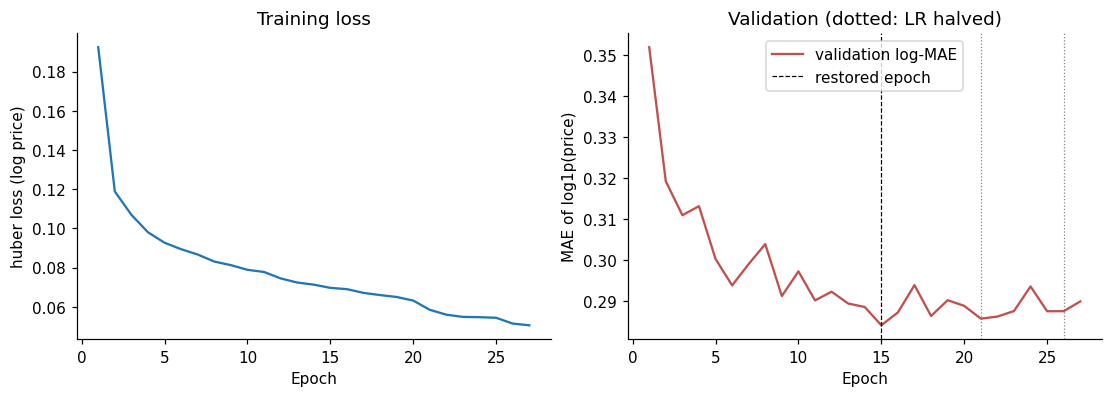

In [8]:
history = histories[selected_index]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
ax[0].plot(history.index, history.train_loss)
ax[0].set(xlabel="Epoch", ylabel=f"{selected_parameters['loss']} loss (log price)", title="Training loss")
ax[1].plot(history.index, history.validation_log_mae, color="#c0504d", label="validation log-MAE")
ax[1].axvline(model.best_epoch_, color="black", linestyle="--", linewidth=.8, label="restored epoch")
for epoch in history.index[history.lr.diff() < 0]:
    ax[1].axvline(epoch, color="grey", linestyle=":", linewidth=.8)
ax[1].set(xlabel="Epoch", ylabel="MAE of log1p(price)", title="Validation (dotted: LR halved)")
ax[1].legend()
plt.show()


## 9. Evaluation

Log-scale predictions are inverse-transformed with `expm1` and bounded between zero and the
maximum training price, using training information only. MAE and RMSE are in VND, R² is
unitless, and MAPE is a percentage. Metrics use the complete partitions, including extreme
values. The scatterplot shows at most 3,000 fixed-seed test listings; the residual histogram
displays the central 98% range only, without removing anything from scoring.


,MAE,RMSE,R2,MAPE
Split,,,,
validation,"4,610,958,859","32,447,885,603",0.3036,"202,681.13"
test,"36,584,217,231","2,964,374,461,424",0.0013,29.74


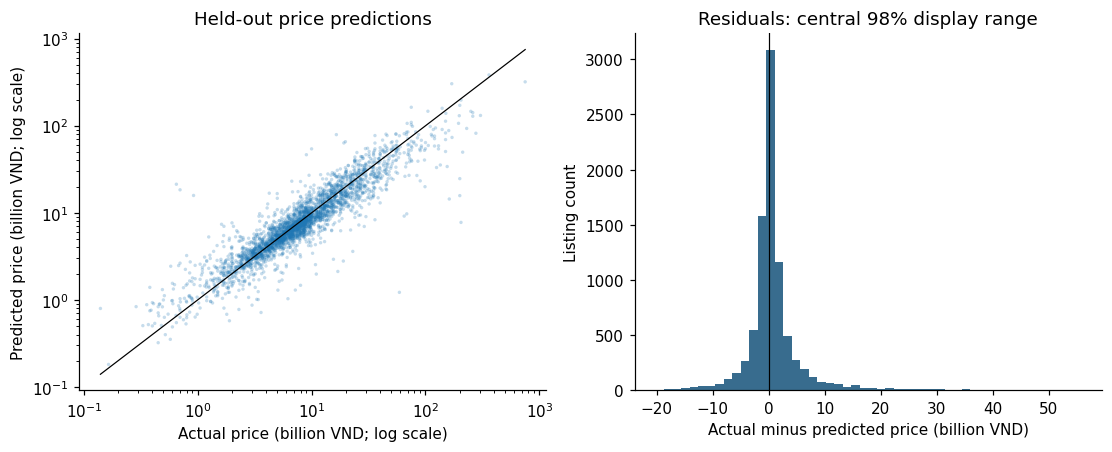

In [9]:
validation_prediction = predict_vnd(model, validation_loader)
test_prediction = predict_vnd(model, test_loader)
extra = {"best_epoch": int(model.best_epoch_), "device": str(DEVICE),
         "trainable_parameters": int(sum(p.numel() for p in model.parameters())),
         "embedding_dimensions": dict(zip(CATEGORICAL, map(embedding_dim, encoder.cardinalities)))}
result, evaluation_table = record_result(
    "mlp", manifest, parts, validation_prediction, test_prediction,
    selected_parameters, tuning_results, extra=extra)
display(evaluation_table.style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}",
                                      "R2": "{:.4f}", "MAPE": "{:,.2f}"}))
diagnostics("mlp", test.price, test_prediction)


## 10. Results and Discussion

**Model selection.** The four candidates reach validation MAE between 4.61 and 4.71 billion VND,
a spread of about 2% from a single seed. This is too small to conclude that larger networks are
better. The robust finding is that Huber and MSE perform almost identically, which suggests that
the conditional log-price distribution is roughly symmetric (Section 7). The validation curve is
noisy after its minimum at epoch 15 (0.284–0.294), so the restored epoch is the lowest point of
a noisy curve, another reason the validation score is optimistic.

**Comparison.** On the held-out test partition the MLP ranks second by MAE (36.58 billion VND),
0.1 billion behind LightGBM (36.48) and ahead of CatBoost (37.21) and Random Forest (37.36). Its
MAPE (29.7%) is likewise second to LightGBM (28.6%). The gap to LightGBM is within what a single
temporal holdout can resolve; the ranking is descriptive, not a significance test.

**Error structure.** Above roughly 100 billion VND the scatterplot points lie below the diagonal,
and the residual histogram is right-skewed: expensive listings are under-predicted. This is the
expected behaviour of a median-targeting model on a long tail, reinforced by the upper bound at
the maximum training price.

**Metric caveats.** Validation MAPE is about 200,000% because a few listings record prices of
only a few million VND, most likely unit errors; MAPE is therefore secondary. Test RMSE and R²
are dominated by a single listing recorded at 280 trillion VND (see `summary.md`), so MAE is the
primary comparison metric.


In [10]:
comparison = comparison_table(manifest)
display(comparison.style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}",
                                 "R2": "{:.4f}", "MAPE": "{:,.2f}"}))
score = result["metrics"]["test"]
display(Markdown(
    f"The held-out test evaluation gives MAE **{score['MAE']:,.0f} VND**, "
    f"RMSE **{score['RMSE']:,.0f} VND**, R² **{score['R2']:.4f}**, "
    f"and MAPE **{score['MAPE']:,.2f}%**."))


,Model,MAE,RMSE,R2,MAPE
0,Dummy Regressor,"45,548,775,416","2,966,493,482,061",-0.0001,259.20
1,Median Price per sqm,"39,768,818,191","2,968,655,086,029",-0.0016,44.85
2,Ridge Regression,"42,681,233,989","2,971,055,734,676",-0.0032,74.73
3,Random Forest,"37,358,517,200","2,965,843,657,508",0.0003,36.77
4,LightGBM,"36,477,344,778","2,964,995,648,314",0.0009,28.59
5,CatBoost,"37,207,498,640","2,964,647,677,804",0.0011,35.56
6,TF-IDF + Ridge,"39,616,175,623","2,966,358,669,831",-0.0000,54.23
7,MLP + Embedding,"36,584,217,231","2,964,374,461,424",0.0013,29.74


The held-out test evaluation gives MAE **36,584,217,231 VND**, RMSE **2,964,374,461,424 VND**, R² **0.0013**, and MAPE **29.74%**.

## 11. Conclusion

An MLP with entity embeddings and residual blocks, trained on log prices with a robust loss,
matches the strongest classical models on structured data: it ranks second, essentially level
with LightGBM. Its main value for this project is that it is differentiable end to end and
produces location embeddings, which the fusion model and the explanation analysis reuse.

Limitations: one seed and a four-point search, validation reused for early stopping and
selection, a single temporal holdout, systematic under-prediction of very expensive listings,
and the protocol-wide caveats on asking prices, entity matching and mixed transaction types.
